# Day 15: Real-World Case Study, Revision and Interview Practice

## Project: E-commerce Customer Conversion and Revenue Analysis

### Business Scenario

An e-commerce company recently introduced a new website design.

The management team wants to understand:

1. How customers are interacting with the website.
2. What percentage of visitors complete a purchase.
3. Whether the new website design improves conversion.
4. Whether the new design improves revenue per visitor.
5. Whether the results are statistically significant.
6. Whether the new design should be implemented.

### Learning Objectives

By the end of this notebook, I will be able to:

- Understand a business problem.
- Generate and inspect a customer-level dataset.
- Perform data-quality checks.
- Calculate business KPIs.
- Analyze customer behavior.
- Apply descriptive statistics.
- Calculate confidence intervals.
- Perform hypothesis testing.
- Analyze relationships between variables.
- Interpret statistical results.
- Prepare business recommendations.
- Revise important statistics concepts.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Display settings
pd.set_option("display.max_columns", None)

# Set random seed for reproducibility
np.random.seed(42)

## 1. Understanding the Business Problem

The company has two website versions.

**Control Group (A):**
Customers use the existing website design.

**Treatment Group (B):**
Customers use the newly designed website.

The company wants to compare both groups.

### Business Questions

1. What is the overall conversion rate?
2. Which group has a higher conversion rate?
3. Is the conversion rate difference statistically significant?
4. Which group generates more revenue per visitor?
5. Is the revenue difference statistically significant?
6. Should the company implement the new website design?

### Key Business Metrics

- Total Visitors
- Total Conversions
- Conversion Rate
- Total Revenue
- Average Revenue per Visitor
- Average Order Value
- Conversion Rate Lift

### Primary Metrics

1. Conversion Rate
2. Revenue per Visitor

We will use these metrics to evaluate the experiment.

In [2]:
# Generate a sample customer-level dataset

n = 2000

customer_id = np.arange(1001, 1001 + n)

# Create two equally sized experiment groups
group = np.array(["A"] * (n // 2) + ["B"] * (n // 2))

# Randomize the order of customers
np.random.shuffle(group)

# Generate customer attributes
age = np.random.randint(18, 61, n)

device = np.random.choice(
    ["Mobile", "Desktop", "Tablet"],
    size=n,
    p=[0.60, 0.30, 0.10]
)

# Generate number of website sessions
sessions = np.random.randint(1, 11, n)

# Generate advertising spend associated with customer acquisition
acquisition_cost = np.random.uniform(5, 30, n)

# Assign conversion probabilities
conversion_probability = np.where(
    group == "A",
    0.10,
    0.12
)

# Generate conversion outcomes
converted = np.random.binomial(
    n=1,
    p=conversion_probability
)

# Generate order value
order_value = np.random.normal(
    loc=120,
    scale=30,
    size=n
)

order_value = np.maximum(order_value, 10)

# Revenue is zero when no purchase occurs
revenue = converted * order_value

# Create DataFrame
df = pd.DataFrame({
    "Customer_ID": customer_id,
    "Group": group,
    "Age": age,
    "Device": device,
    "Sessions": sessions,
    "Acquisition_Cost": acquisition_cost,
    "Converted": converted,
    "Order_Value": order_value,
    "Revenue": revenue
})

df.head()

,Customer_ID,Group,Age,Device,Sessions,Acquisition_Cost,Converted,Order_Value,Revenue
0,1001,B,54,Desktop,7,19.053619,0,78.344693,0.0
1,1002,A,22,Mobile,10,18.817597,0,93.225479,0.0
2,1003,B,18,Mobile,2,7.868549,0,26.500415,0.0
3,1004,A,57,Desktop,4,8.153441,0,121.559761,0.0
4,1005,B,29,Tablet,5,18.238340,0,159.121994,0.0


## 2. Data Understanding and Data Quality

Before performing statistical analysis,
we should understand the dataset.

Important checks include:

- Number of rows and columns
- Column data types
- Missing values
- Duplicate records
- Unique customer IDs
- Valid conversion values
- Negative revenue values

Data-quality checks help prevent incorrect conclusions.

In [3]:
# Inspect the dataset

print("Dataset Shape:")
print(df.shape)

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(2000, 9)

First Five Rows:


,Customer_ID,Group,Age,Device,Sessions,Acquisition_Cost,Converted,Order_Value,Revenue
0,1001,B,54,Desktop,7,19.053619,0,78.344693,0.0
1,1002,A,22,Mobile,10,18.817597,0,93.225479,0.0
2,1003,B,18,Mobile,2,7.868549,0,26.500415,0.0
3,1004,A,57,Desktop,4,8.153441,0,121.559761,0.0
4,1005,B,29,Tablet,5,18.238340,0,159.121994,0.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       2000 non-null   int64  
 1   Group             2000 non-null   object 
 2   Age               2000 non-null   int64  
 3   Device            2000 non-null   object 
 4   Sessions          2000 non-null   int64  
 5   Acquisition_Cost  2000 non-null   float64
 6   Converted         2000 non-null   int64  
 7   Order_Value       2000 non-null   float64
 8   Revenue           2000 non-null   float64
dtypes: float64(3), int64(4), object(2)
memory usage: 140.8+ KB

Statistical Summary:


,Customer_ID,Age,Sessions,Acquisition_Cost,Converted,Order_Value,Revenue
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,2000.500000,38.997000,5.572500,17.132404,0.101000,120.069504,12.107872
std,577.494589,12.278166,2.906022,7.173096,0.301404,29.977320,37.500787
min,1001.000000,18.000000,1.000000,5.006025,0.000000,25.757564,0.000000
25%,1500.750000,28.000000,3.000000,10.882386,0.000000,99.781614,0.000000
50%,2000.500000,39.000000,6.000000,17.019870,0.000000,119.547531,0.000000
75%,2500.250000,50.000000,8.000000,23.243277,0.000000,140.277876,0.000000
max,3000.000000,60.000000,10.000000,29.980182,1.000000,226.321950,206.749761


In [4]:
# Perform data-quality checks

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Customer IDs:")
print(df["Customer_ID"].duplicated().sum())

print("\nConversion Values:")
print(df["Converted"].value_counts())

print("\nNegative Revenue Records:")
print((df["Revenue"] < 0).sum())

Missing Values:
Customer_ID         0
Group               0
Age                 0
Device              0
Sessions            0
Acquisition_Cost    0
Converted           0
Order_Value         0
Revenue             0
dtype: int64

Duplicate Rows:
0

Duplicate Customer IDs:
0

Conversion Values:
Converted
0    1798
1     202
Name: count, dtype: int64

Negative Revenue Records:
0


### Data Quality Interpretation

Review the outputs and confirm:

- Every customer has a unique ID.
- There are no unexpected missing values.
- There are no duplicate customer records.
- Conversion contains only 0 and 1.
- Revenue is not negative.

**Important:**

A clean dataset does not automatically mean
that the analysis is correct.

We must also check whether the data represents
the intended business population and experiment design.

In [5]:
# Check experiment group distribution

group_distribution = (
    df["Group"]
    .value_counts()
    .rename_axis("Group")
    .reset_index(name="Customers")
)

group_distribution["Percentage"] = (
    group_distribution["Customers"]
    / len(df) * 100
)

display(group_distribution)

,Group,Customers,Percentage
0,B,1000,50.0
1,A,1000,50.0


## 3. Descriptive Statistics and Business KPIs

Descriptive statistics help us summarize
the overall business performance.

We will calculate:

- Total Visitors
- Total Conversions
- Overall Conversion Rate
- Total Revenue
- Average Revenue per Visitor
- Average Order Value

### Formulas

Conversion Rate:

(Conversions / Visitors) × 100

Revenue per Visitor:

Total Revenue / Total Visitors

Average Order Value:

Total Revenue / Total Orders

**Important:**

Revenue per visitor includes visitors who did not purchase.
Average order value considers only completed orders.

In [6]:
# Calculate overall business KPIs

total_visitors = len(df)

total_conversions = df["Converted"].sum()

total_revenue = df["Revenue"].sum()

overall_conversion_rate = (
    total_conversions / total_visitors * 100
)

revenue_per_visitor = (
    total_revenue / total_visitors
)

average_order_value = (
    total_revenue / total_conversions
    if total_conversions > 0 else 0
)

print("Total Visitors:", total_visitors)

print("Total Conversions:", total_conversions)

print("Overall Conversion Rate:",
      round(overall_conversion_rate, 2), "%")

print("Total Revenue:",
      round(total_revenue, 2))

print("Revenue per Visitor:",
      round(revenue_per_visitor, 2))

print("Average Order Value:",
      round(average_order_value, 2))

Total Visitors: 2000
Total Conversions: 202
Overall Conversion Rate: 10.1 %
Total Revenue: 24215.74
Revenue per Visitor: 12.11
Average Order Value: 119.88


In [7]:
# Analyze business performance by experiment group

group_summary = (
    df.groupby("Group")
    .agg(
        Visitors=("Customer_ID", "count"),
        Conversions=("Converted", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
)

group_summary["Conversion_Rate"] = (
    group_summary["Conversions"]
    / group_summary["Visitors"] * 100
)

group_summary["Revenue_Per_Visitor"] = (
    group_summary["Total_Revenue"]
    / group_summary["Visitors"]
)

group_summary["Average_Order_Value"] = (
    group_summary["Total_Revenue"]
    / group_summary["Conversions"]
)

display(group_summary.round(2))

,Visitors,Conversions,Total_Revenue,Conversion_Rate,Revenue_Per_Visitor,Average_Order_Value
Group,,,,,,
A,1000,88,10231.57,8.8,10.23,116.27
B,1000,114,13984.18,11.4,13.98,122.67


## 4. Customer Behavior Analysis

Customer behavior analysis helps us understand
how different customer groups interact with the website.

We will analyze:

- Conversion by device
- Average sessions by device
- Revenue by device
- Conversion by age group

### Business Questions

1. Which device category has the highest conversion rate?
2. Which device category generates the most revenue?
3. Does customer age appear related to conversion?
4. Which customer segment should the business investigate further?

Remember that these comparisons are descriptive.
They do not automatically establish causation.

In [8]:
# Create age groups

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 60],
    labels=["18-25", "26-35", "36-45", "46-55", "56-60"]
)

# Analyze conversion by device

device_summary = (
    df.groupby("Device", observed=True)
    .agg(
        Visitors=("Customer_ID", "count"),
        Conversions=("Converted", "sum"),
        Revenue=("Revenue", "sum"),
        Average_Sessions=("Sessions", "mean")
    )
)

device_summary["Conversion_Rate"] = (
    device_summary["Conversions"]
    / device_summary["Visitors"] * 100
)

device_summary["Revenue_Per_Visitor"] = (
    device_summary["Revenue"]
    / device_summary["Visitors"]
)

display(device_summary.round(2))

,Visitors,Conversions,Revenue,Average_Sessions,Conversion_Rate,Revenue_Per_Visitor
Device,,,,,,
Desktop,603,59,7170.59,5.43,9.78,11.89
Mobile,1216,128,15055.77,5.65,10.53,12.38
Tablet,181,15,1989.38,5.57,8.29,10.99


In [9]:
# Analyze conversion by age group

age_summary = (
    df.groupby("Age_Group", observed=True)
    .agg(
        Visitors=("Customer_ID", "count"),
        Conversions=("Converted", "sum"),
        Revenue=("Revenue", "sum")
    )
)

age_summary["Conversion_Rate"] = (
    age_summary["Conversions"]
    / age_summary["Visitors"] * 100
)

display(age_summary.round(2))

,Visitors,Conversions,Revenue,Conversion_Rate
Age_Group,,,,
18-25,365,49,5835.02,13.42
26-35,454,41,4915.34,9.03
36-45,498,48,5697.64,9.64
46-55,468,42,5067.94,8.97
56-60,215,22,2699.80,10.23


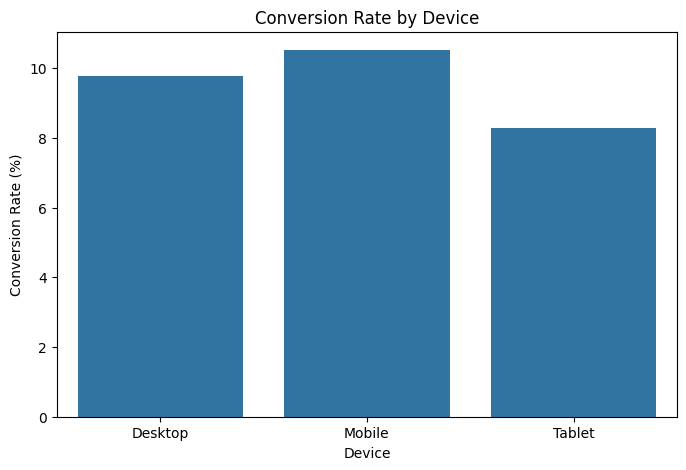

In [10]:
# Visualize conversion rate by device

plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_summary.reset_index(),
    x="Device",
    y="Conversion_Rate"
)

plt.title("Conversion Rate by Device")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")

plt.show()

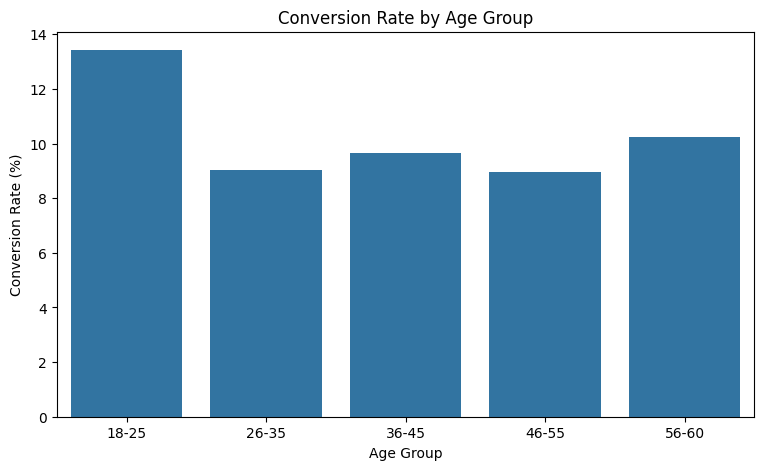

In [11]:
# Visualize conversion rate by age group

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_summary.reset_index(),
    x="Age_Group",
    y="Conversion_Rate"
)

plt.title("Conversion Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Conversion Rate (%)")

plt.show()

## 5. Confidence Interval for Conversion Rate

A confidence interval provides a range of plausible
values for the population conversion rate.

We will calculate an approximate 95% confidence interval
for the overall conversion rate.

### Formula

Sample Proportion ± Z Critical Value × Standard Error

Where:

Standard Error = sqrt(p × (1-p) / n)

For a 95% confidence interval,
the standard normal critical value is approximately 1.96.

### Interpretation

A 95% confidence interval means that
if we repeatedly collected samples and constructed intervals
using the same method, approximately 95% of those intervals
would contain the true population proportion.

It does not mean there is a 95% probability
that the fixed population parameter lies inside
this particular calculated interval.

In [12]:
# Calculate 95% confidence interval for overall conversion rate

p = total_conversions / total_visitors

standard_error = np.sqrt(
    p * (1 - p) / total_visitors
)

z_critical = stats.norm.ppf(0.975)

margin_of_error = z_critical * standard_error

lower_limit = p - margin_of_error
upper_limit = p + margin_of_error

print("Overall Conversion Rate:", round(p * 100, 2), "%")

print(
    "95% Confidence Interval:",
    (round(lower_limit * 100, 2),
     round(upper_limit * 100, 2)),
    "%"
)

Overall Conversion Rate: 10.1 %
95% Confidence Interval: (np.float64(8.78), np.float64(11.42)) %


## 6. A/B Testing and Hypothesis Testing

Now we will evaluate whether the new website design
has improved the conversion rate.

### Hypotheses

Null Hypothesis (H0):

The conversion rates of Group A and Group B are equal.

Alternative Hypothesis (H1):

The conversion rates of Group A and Group B are different.

### Statistical Test

We will use a two-proportion Z-test.

### Significance Level

Alpha = 0.05

Decision:

- p-value < 0.05: Reject H0.
- p-value >= 0.05: Do not reject H0.

The test assumes independent groups and
a sufficiently large sample for the normal approximation.

In [13]:
# Extract conversion counts for both groups

conversions = (
    df.groupby("Group")["Converted"]
    .sum()
    .reindex(["A", "B"])
)

visitors = (
    df.groupby("Group")["Customer_ID"]
    .count()
    .reindex(["A", "B"])
)

print("Conversions:")
print(conversions)

print("\nVisitors:")
print(visitors)

# Calculate conversion rates

conversion_rates = conversions / visitors * 100

print("\nConversion Rates:")
print(conversion_rates.round(2))

Conversions:
Group
A     88
B    114
Name: Converted, dtype: int64

Visitors:
Group
A    1000
B    1000
Name: Customer_ID, dtype: int64

Conversion Rates:
Group
A     8.8
B    11.4
dtype: float64


In [14]:
# Perform two-proportion Z-test

z_stat, p_value = proportions_ztest(
    count=conversions.values,
    nobs=visitors.values,
    alternative="two-sided"
)

print("Z-Statistic:", round(z_stat, 4))

print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis")
else:
    print("\nDecision: Do Not Reject the Null Hypothesis")

Z-Statistic: -1.9294
P-value: 0.053683679893802336

Decision: Do Not Reject the Null Hypothesis


In [15]:
# Calculate absolute and relative conversion rate lift

rate_a = conversion_rates.loc["A"]

rate_b = conversion_rates.loc["B"]

absolute_lift = rate_b - rate_a

relative_lift = (
    (rate_b - rate_a) / rate_a
) * 100

print("Control Conversion Rate:", round(rate_a, 2), "%")

print("Treatment Conversion Rate:", round(rate_b, 2), "%")

print("Absolute Lift:",
      round(absolute_lift, 2), "percentage points")

print("Relative Lift:",
      round(relative_lift, 2), "%")

Control Conversion Rate: 8.8 %
Treatment Conversion Rate: 11.4 %
Absolute Lift: 2.6 percentage points
Relative Lift: 29.55 %


## 7. Confidence Interval for A/B Conversion Difference

We will calculate an approximate 95% confidence interval
for the difference:

Treatment Conversion Rate - Control Conversion Rate

A positive difference means the Treatment group
has a higher observed conversion rate.

If the confidence interval does not contain zero,
the difference is statistically significant
at approximately the 5% level for a two-sided test,
under the large-sample assumptions.

This interval uses the unpooled standard error.

In [16]:
# Calculate confidence interval for conversion rate difference

p_a = conversions.loc["A"] / visitors.loc["A"]

p_b = conversions.loc["B"] / visitors.loc["B"]

difference = p_b - p_a

se_difference = np.sqrt(
    (p_a * (1 - p_a) / visitors.loc["A"])
    +
    (p_b * (1 - p_b) / visitors.loc["B"])
)

z_critical = stats.norm.ppf(0.975)

lower_bound = difference - z_critical * se_difference

upper_bound = difference + z_critical * se_difference

print("Conversion Rate Difference (B - A):",
      round(difference * 100, 2), "percentage points")

print(
    "95% Confidence Interval:",
    (
        round(lower_bound * 100, 2),
        round(upper_bound * 100, 2)
    ),
    "percentage points"
)

Conversion Rate Difference (B - A): 2.6 percentage points
95% Confidence Interval: (np.float64(-0.04), np.float64(5.24)) percentage points


## 8. Revenue per Visitor Analysis

A higher conversion rate does not necessarily
mean that the business generates more revenue per visitor.

We will compare revenue per visitor between both groups.

Revenue per Visitor = Total Revenue / Total Visitors

Since each customer has a revenue value,
including zero for non-purchasers,
we can compare the two independent groups
using Welch's T-test.

### Hypotheses

H0: Mean revenue per visitor is equal in both groups.

H1: Mean revenue per visitor differs between both groups.

We use Welch's T-test because it does not require
equal population variances.

In [17]:
# Separate revenue values by group

revenue_a = df.loc[
    df["Group"] == "A",
    "Revenue"
]

revenue_b = df.loc[
    df["Group"] == "B",
    "Revenue"
]

# Compare revenue per visitor

revenue_comparison = pd.DataFrame({
    "Group": ["A", "B"],
    "Visitors": [len(revenue_a), len(revenue_b)],
    "Total_Revenue": [revenue_a.sum(), revenue_b.sum()],
    "Revenue_Per_Visitor": [
        revenue_a.mean(),
        revenue_b.mean()
    ]
})

display(revenue_comparison.round(2))

,Group,Visitors,Total_Revenue,Revenue_Per_Visitor
0,A,1000,10231.57,10.23
1,B,1000,13984.18,13.98


In [18]:
# Perform Welch's independent two-sample T-test

t_stat, revenue_p_value = stats.ttest_ind(
    revenue_a,
    revenue_b,
    equal_var=False,
    alternative="two-sided"
)

print("T-Statistic:", round(t_stat, 4))

print("P-value:", revenue_p_value)

if revenue_p_value < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
else:
    print("\nDecision: Do Not Reject the Null Hypothesis")

T-Statistic: -2.2398
P-value: 0.025214696424725073

Decision: Reject the Null Hypothesis


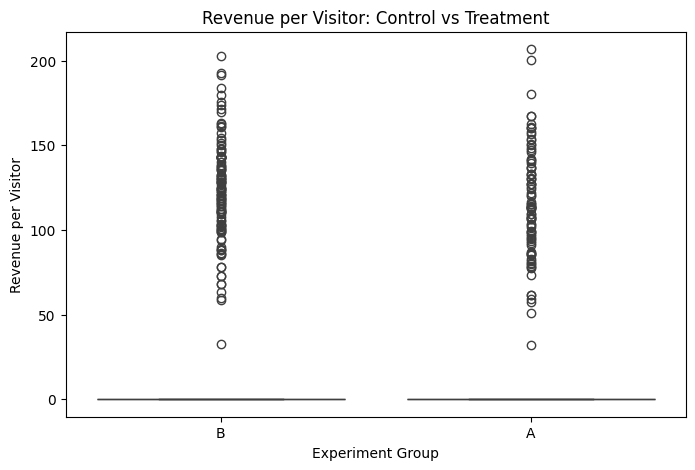

In [19]:
# Visualize revenue per visitor

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Group",
    y="Revenue"
)

plt.title("Revenue per Visitor: Control vs Treatment")
plt.xlabel("Experiment Group")
plt.ylabel("Revenue per Visitor")

plt.show()

## 9. Correlation Analysis

Correlation helps us understand
the direction and strength of linear relationships
between numerical variables.

We will examine relationships between:

- Age
- Sessions
- Acquisition Cost
- Converted
- Revenue

**Important:**

A correlation between two variables
does not prove that one causes the other.

Binary variables such as Converted can be included
in Pearson correlation calculations,
but their interpretation requires care.

In [20]:
# Calculate correlation matrix

numeric_columns = [
    "Age",
    "Sessions",
    "Acquisition_Cost",
    "Converted",
    "Revenue"
]

correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix)

,Age,Sessions,Acquisition_Cost,Converted,Revenue
Age,1.000000,0.051208,-0.015075,-0.034388,-0.031168
Sessions,0.051208,1.000000,-0.004138,-0.003795,-0.005590
Acquisition_Cost,-0.015075,-0.004138,1.000000,-0.013104,-0.010007
Converted,-0.034388,-0.003795,-0.013104,1.000000,0.963508
Revenue,-0.031168,-0.005590,-0.010007,0.963508,1.000000


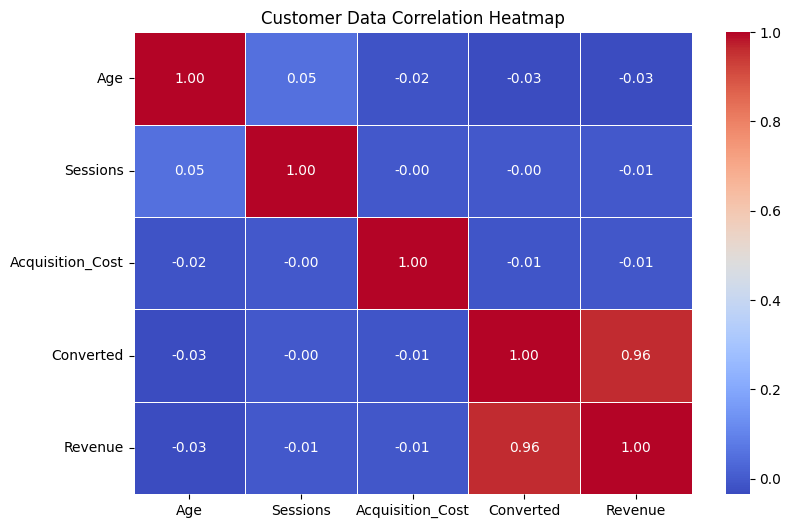

In [21]:
# Visualize correlation matrix

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Data Correlation Heatmap")

plt.show()

## 10. Business Insights and Recommendations

After completing the analysis,
a Data Analyst should convert statistical results
into understandable business insights.

### Questions to Answer

1. Which group has the higher conversion rate?
2. What is the absolute conversion rate lift?
3. Is the conversion difference statistically significant?
4. Which group has higher revenue per visitor?
5. Is the revenue difference statistically significant?
6. What do the customer segments reveal?
7. What should management do next?

### Business Decision Framework

- Consider the primary KPI.
- Review statistical significance.
- Review confidence intervals.
- Evaluate practical business impact.
- Check secondary and guardrail metrics.
- Consider experiment quality and limitations.

**Important:**

Do not recommend implementing a change
based only on a higher observed conversion rate.
Consider uncertainty, revenue, customer experience,
and experiment design.

In [22]:
# Prepare a final business comparison

final_summary = (
    df.groupby("Group")
    .agg(
        Visitors=("Customer_ID", "count"),
        Conversions=("Converted", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Revenue_Per_Visitor=("Revenue", "mean")
    )
)

final_summary["Conversion_Rate"] = (
    final_summary["Conversions"]
    / final_summary["Visitors"] * 100
)

display(final_summary.round(2))

print("Conversion Test P-value:", round(p_value, 6))

print("Revenue Test P-value:", round(revenue_p_value, 6))

,Visitors,Conversions,Total_Revenue,Revenue_Per_Visitor,Conversion_Rate
Group,,,,,
A,1000,88,10231.57,10.23,8.8
B,1000,114,13984.18,13.98,11.4


Conversion Test P-value: 0.053684
Revenue Test P-value: 0.025215


In [23]:
# Generate a basic evidence-based recommendation

if p_value < 0.05 and revenue_p_value < 0.05:
    print(
        "Both conversion rate and revenue per visitor "
        "show statistically significant differences."
    )

    print(
        "Review the direction and size of both differences "
        "before considering implementation."
    )

elif p_value < 0.05:
    print(
        "Conversion rate shows a statistically significant difference, "
        "but revenue per visitor does not."
    )

    print(
        "Evaluate the business value and monitor revenue "
        "before making a final decision."
    )

elif revenue_p_value < 0.05:
    print(
        "Revenue per visitor shows a statistically significant difference, "
        "but conversion rate does not."
    )

    print(
        "Investigate the revenue impact and customer behavior "
        "before making a final decision."
    )

else:
    print(
        "Neither metric shows a statistically significant difference "
        "at the 5% significance level."
    )

    print(
        "There is insufficient statistical evidence "
        "to establish an improvement."
    )

Revenue per visitor shows a statistically significant difference, but conversion rate does not.
Investigate the revenue impact and customer behavior before making a final decision.


## 11. Limitations of This Case Study

This notebook uses simulated customer data
for learning and practice.

The results should not be treated as findings
from a real company's experiment.

### Important Limitations

1. The dataset is simulated.
2. Conversion probabilities were predefined.
3. The experiment assumes independent observations.
4. We have not performed a formal sample-size calculation.
5. We have not tested every possible experiment assumption.
6. Customer segments may have additional confounding factors.
7. The experiment does not represent every business scenario.

### Real-World Considerations

Before making an actual business decision:

- Validate data collection and tracking.
- Confirm proper random assignment.
- Check sample ratio mismatch.
- Define the primary metric in advance.
- Calculate the required sample size.
- Choose an appropriate experiment duration.
- Monitor guardrail metrics.
- Consider costs and long-term impact.

## 12. Statistics Revision Cheat Sheet

| Topic | Important Concept |
|---|---|
| Mean | Average of observations |
| Median | Middle value |
| Mode | Most frequently occurring value |
| Range | Maximum - Minimum |
| Variance | Average squared deviation |
| Standard Deviation | Square root of variance |
| IQR | Q3 - Q1 |
| Skewness | Asymmetry of a distribution |
| Kurtosis | Tail heaviness relative to normal distribution |
| Probability | Likelihood of an event |
| Conditional Probability | Probability given another event |
| Bayes' Theorem | Updates probability using new evidence |
| Normal Distribution | Symmetric bell-shaped distribution |
| CLT | Sampling means approach normality under suitable conditions |
| Standard Error | Standard deviation of a sampling distribution |
| Confidence Interval | Range of plausible parameter values |
| Hypothesis Testing | Method for evaluating statistical evidence |
| P-value | Probability of an equally or more extreme result under H0 |
| Type I Error | Rejecting a true null hypothesis |
| Type II Error | Failing to reject a false null hypothesis |
| Chi-Square Test | Tests categorical frequency patterns or association |
| ANOVA | Compares three or more group means |
| Covariance | Direction of joint variation |
| Correlation | Strength and direction of association |
| Regression | Models relationships and predicts outcomes |
| A/B Testing | Compares alternatives through an experiment |

### Important Formulas

Mean:

Mean = Sum of Values / Number of Values

Standard Deviation:

SD = Square Root of Variance

IQR:

IQR = Q3 - Q1

Z-Score:

Z = (X - Mean) / Standard Deviation

Standard Error of Mean:

SE = Sample SD / Square Root of Sample Size

Conversion Rate:

Conversions / Visitors × 100

Revenue per Visitor:

Total Revenue / Total Visitors

Absolute Lift:

Treatment Rate - Control Rate

Relative Lift:

((Treatment Rate - Control Rate) / Control Rate) × 100

## 13. Interview Preparation

### Q1. What is the difference between descriptive
and inferential statistics?

Descriptive statistics summarize available data.
Inferential statistics use sample data
to draw conclusions about a population.

### Q2. What is the difference between mean and median?

Mean is the arithmetic average.
Median is the middle value after sorting observations.

Median is generally less affected by extreme values.

### Q3. What is standard deviation?

It measures how spread out observations are
around the mean.

### Q4. What is the Central Limit Theorem?

Under suitable conditions, the sampling distribution
of the sample mean approaches a normal distribution
as the sample size increases.

### Q5. What is a confidence interval?

It is an interval estimate constructed using
a statistical method to provide plausible values
for a population parameter.

### Q6. What is a p-value?

It is the probability, assuming the null hypothesis
and test assumptions are correct, of observing
a result at least as extreme as the observed result.

### Q7. What is the difference between Type I and Type II errors?

Type I error means rejecting a true null hypothesis.
Type II error means failing to reject a false null hypothesis.

### Q8. When would you use a Chi-Square test?

To analyze categorical frequency data,
such as testing independence between two categorical variables.

### Q9. What is ANOVA?

ANOVA is used to compare means across
three or more independent groups.

### Q10. What is the difference between correlation and causation?

Correlation indicates association.
Causation means a change in one variable
produces a change in another.

### Q11. What is Linear Regression?

It models the relationship between a target variable
and one or more independent variables using a linear equation.

### Q12. What is R-squared?

It measures how much variation in the target variable
is explained by the model relative to a mean baseline.

### Q13. What is A/B Testing?

It is an experimental method used to compare
two versions of a product or business strategy.

### Q14. Why is randomization important in A/B testing?

It helps reduce selection bias
and makes the groups more comparable.

### Q15. What is the difference between statistical
and practical significance?

Statistical significance relates to evidence
against the null hypothesis.

Practical significance relates to whether
the observed effect matters in the real business context.

### Q16. Which statistical concepts are especially
important for a Data Analyst?

Descriptive statistics, probability, sampling,
hypothesis testing, correlation, regression,
and business KPI analysis are especially useful.

## 14. Final Independent Assessment

Try answering these questions without referring
to the previous sections.

### Part A — Concepts

1. What is the difference between population and sample?
2. Why is median preferred for highly skewed data?
3. What does a high standard deviation indicate?
4. What is the difference between variance and standard deviation?
5. Can correlation be zero when a nonlinear relationship exists?
6. Why do we use a confidence interval?
7. What does a p-value below 0.05 indicate?
8. What is the difference between Type I and Type II errors?

### Part B — Statistical Methods

9. When would you use a T-test?
10. When would you use a Chi-Square test?
11. When would you use ANOVA?
12. What is the difference between Pearson and Spearman correlation?
13. Why do we split data into training and testing sets?
14. Why is Welch's T-test useful?
15. Which test can compare two conversion rates?

### Part C — Business Scenarios

16. A store has high revenue but low profit margin.
    What would you investigate?

17. A marketing campaign has a higher conversion rate
    but a lower average order value.
    How would you evaluate its performance?

18. A/B testing produces a p-value of 0.03.
    What would you conclude?

19. A/B testing produces a p-value of 0.40.
    Does this prove both versions are identical?

20. A new website design improves conversion rate
    but increases refund rate.
    What would you recommend?

### Part D — Practical Python

21. Calculate mean, median and standard deviation.
22. Calculate IQR and identify outliers.
23. Calculate Pearson correlation.
24. Perform a one-sample or independent T-test.
25. Create a correlation heatmap.
26. Build a Linear Regression model.
27. Calculate MAE, RMSE and R-squared.
28. Perform a two-proportion Z-test.

**Assessment Goal:**

Try to explain both the statistical result
and its business meaning.

## 15. Final Course Conclusion

Congratulations on completing the 15-day
Statistics learning roadmap!

### What I Have Covered

**Descriptive Statistics**
- Central Tendency
- Dispersion
- Percentiles and Quartiles
- Outlier Detection
- Skewness and Kurtosis

**Probability**
- Probability Rules
- Conditional Probability
- Bayes' Theorem
- Probability Distributions
- Normal Distribution

**Sampling and Inference**
- Sampling Techniques
- Sampling Distribution
- Central Limit Theorem
- Standard Error
- Confidence Intervals

**Hypothesis Testing**
- Z-Test
- T-Test
- Chi-Square Test
- ANOVA
- Statistical Errors

**Correlation and Regression**
- Covariance
- Pearson and Spearman Correlation
- Linear Regression
- Model Evaluation

**Business Statistics**
- Business KPIs
- A/B Testing
- Conversion Analysis
- Revenue Analysis
- Business Decision-Making

### Final Takeaway

Statistics is not only about formulas and calculations.

For a Data Analyst, the real objective is to:

1. Understand the business problem.
2. Analyze the available data.
3. Select the appropriate statistical method.
4. Interpret the results correctly.
5. Communicate meaningful business insights.
6. Support better decisions using data.

**Statistics Learning Roadmap: Completed — 15/15 Days.**

The next step is to strengthen these concepts
through practical SQL, Python, Excel, Power BI,
and real-world Data Analytics projects.